<a href="https://colab.research.google.com/github/KacChw/Machine-Learning-Labolatory-Master-Course-Big-Data/blob/main/ML_Cw03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

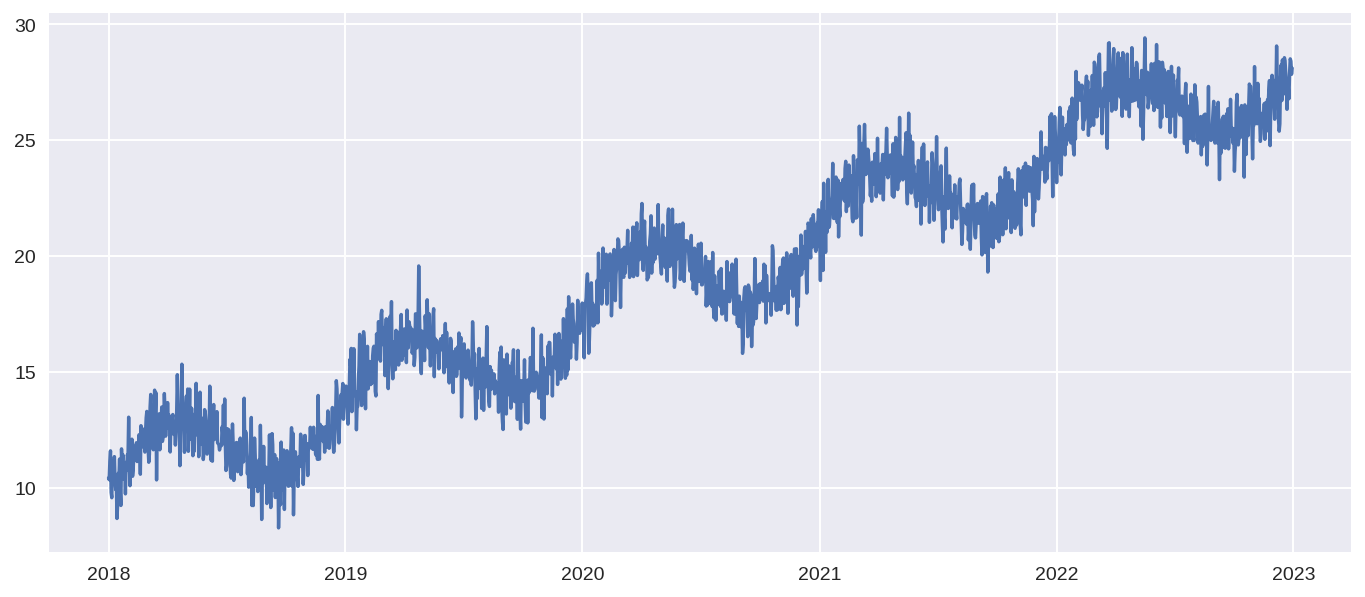

staty                  y
count  1825.000000
mean     19.155089
std       5.325944
min       8.279225
25%      14.629273
50%      19.265883
75%      23.704415
max      29.420365 

Zakres 2018-01-01 -> 2022-12-30


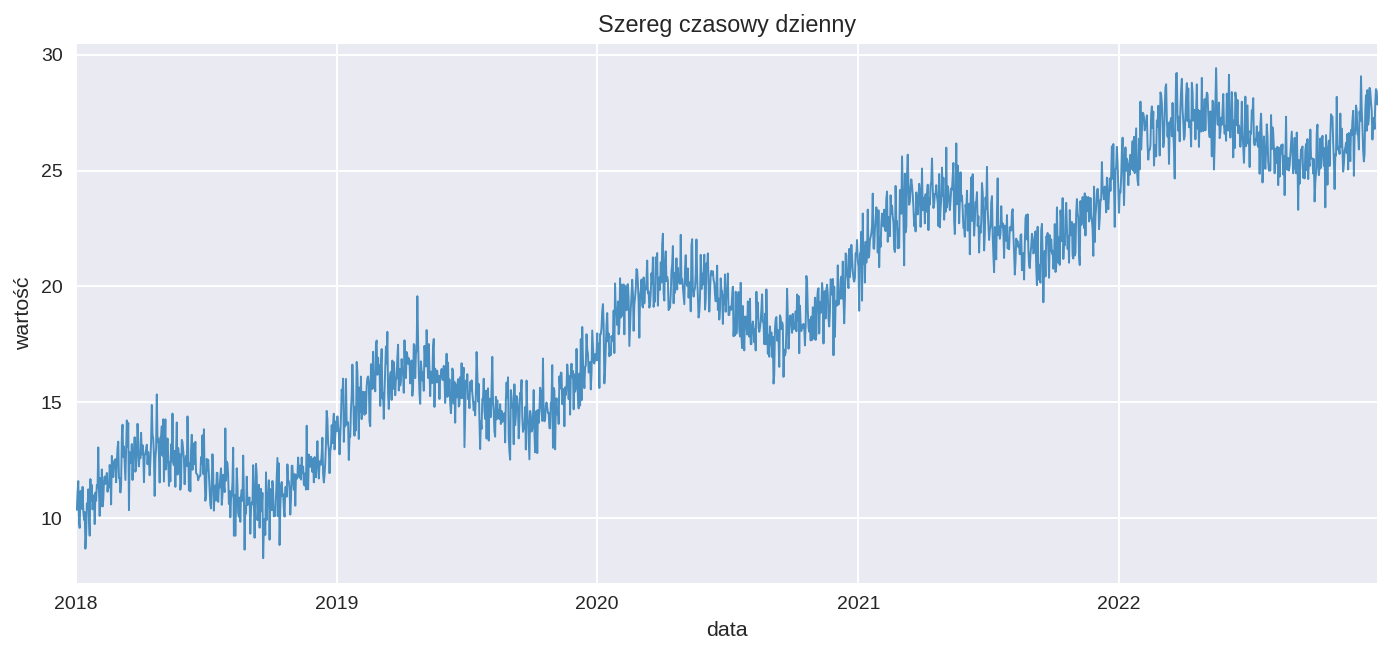

In [7]:
# podstawy analizy szeregow czasowych w pandas

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas.plotting import lag_plot, autocorrelation_plot

plt.style.use("seaborn-v0_8")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 140

rng_seed =42
np.random.seed(rng_seed)

idx = pd.date_range("2018-01-01", periods=5*365, freq="D")

n = len(idx)
t = np.arange(n)

poziom = 10.0
trend = t * 0.01

sezon_roczny = 2.0 * np.sin(2 * np.pi * idx.dayofyear / 365.25)
sezon_tyg = 0.5 * np.sin(2*np.pi * idx.dayofweek / 7)
szum = np.random.normal(loc=0.0, scale=0.8, size=n)

y = poziom + trend + sezon_roczny + sezon_tyg + szum
plt.figure()
plt.plot(idx, y)
plt.show()

# lepiej do ramki
df = pd.DataFrame({"y":y}, index=idx)
df.index.name = "data"

print("staty", df.describe(), "\n")
print("Zakres", df.index.min().date(), "->", df.index.max().date())

ax = df["y"].plot(color="tab:blue", alpha=0.8, lw=1.0, title="Szereg czasowy dzienny")
ax.set_xlabel("data")
ax.set_ylabel("wartość")
ax.grid(True)
plt.show()

/tmp/ipykernel_5378/3301745222.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  y_month = df["y"].resample("M").mean()


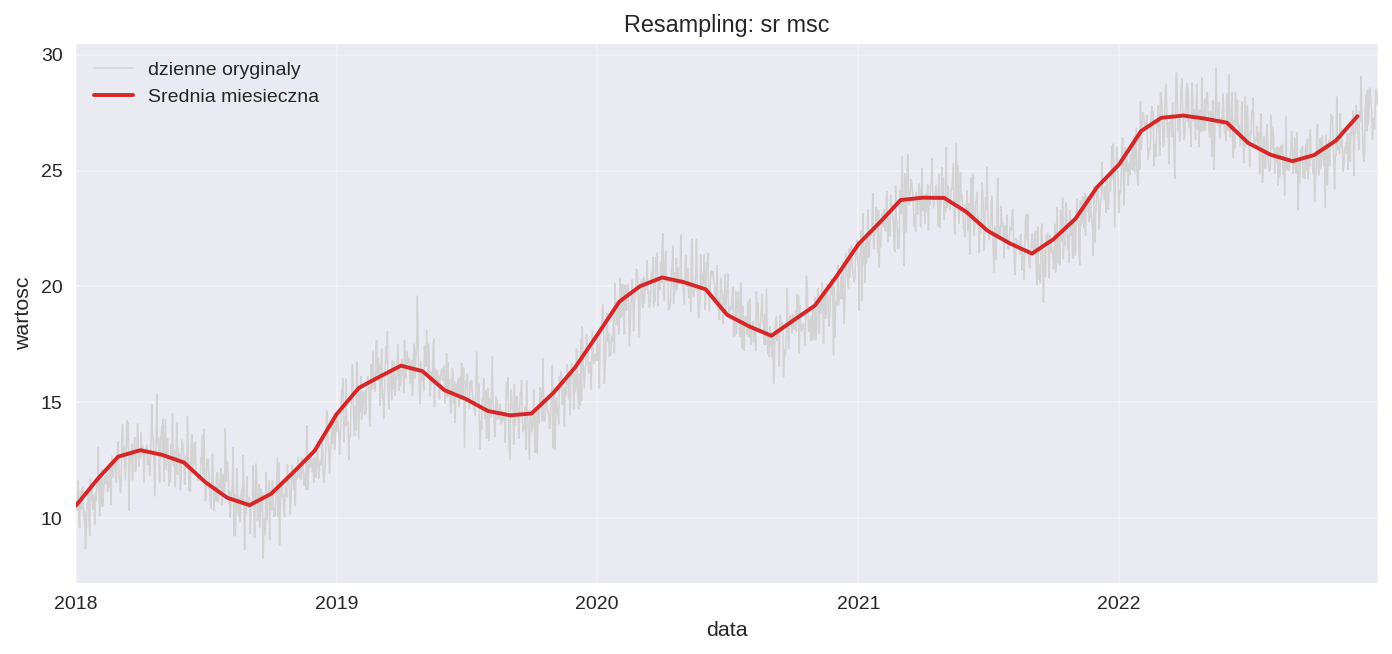

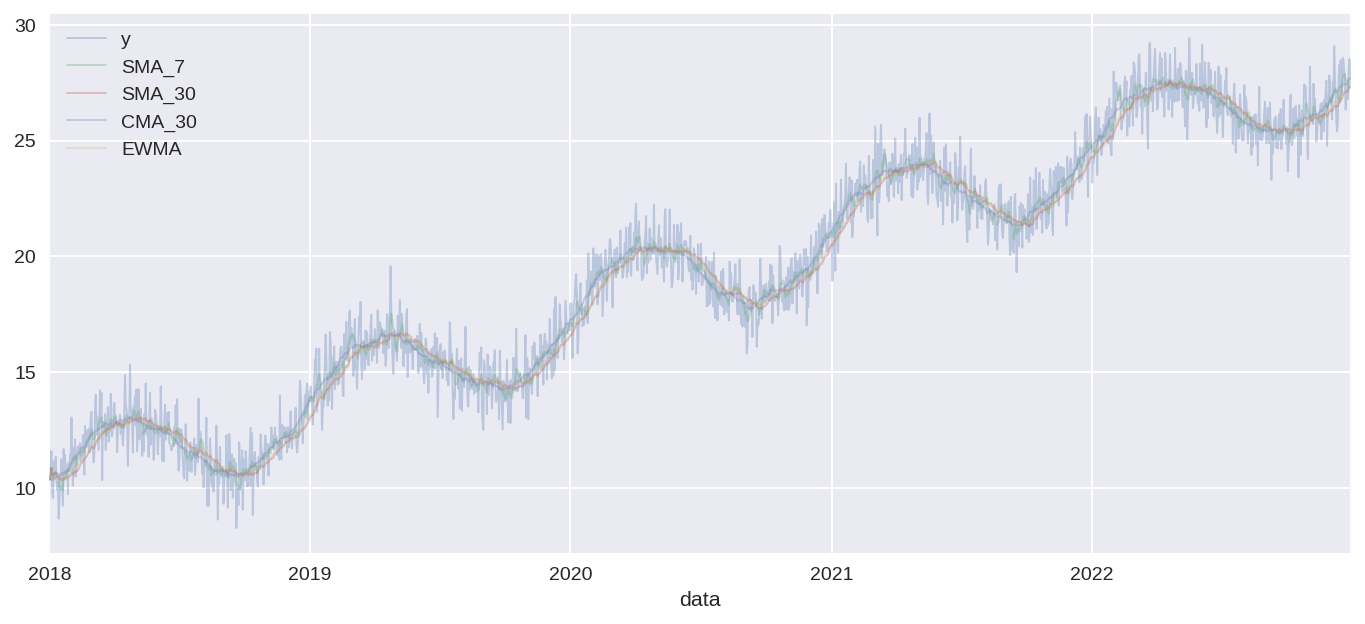

In [10]:
# resampling - usrednianie miesieczne i nakladka na serie dzienna

y_month = df["y"].resample("M").mean()

ax = df["y"].plot(color="lightgray", lw=0.8, label="dzienne oryginaly")

y_month.plot(ax=ax, color="tab:red", lw=2, label="Srednia miesieczna")

ax.set_title("Resampling: sr msc")
ax.set_xlabel("data")
ax.set_ylabel("wartosc")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

# srednie ruchome SMA, CMA i wygladzanie wykladnicze EWMA
# SMA_7 prosta ruhcoma 7 dniowa
# SMA_30
# CMA_30 - centrowa 30 dniowa
# EWMA - wykladnicze wygladzanie

df["SMA_7"] = df["y"].rolling(window=7, min_periods=1, center=False).mean()
df["SMA_30"] = df["y"].rolling(window=30, min_periods=1, center=False).mean()
df["CMA_30"] = df["y"].rolling(window=30, min_periods=15, center=True).mean()
df["EWMA"] = df["y"].ewm(span=30, adjust=False).mean()

# wykres tych czterech
ax = df[["y", "SMA_7", "SMA_30", "CMA_30", "EWMA"]].plot(lw=1.0, alpha=0.3)

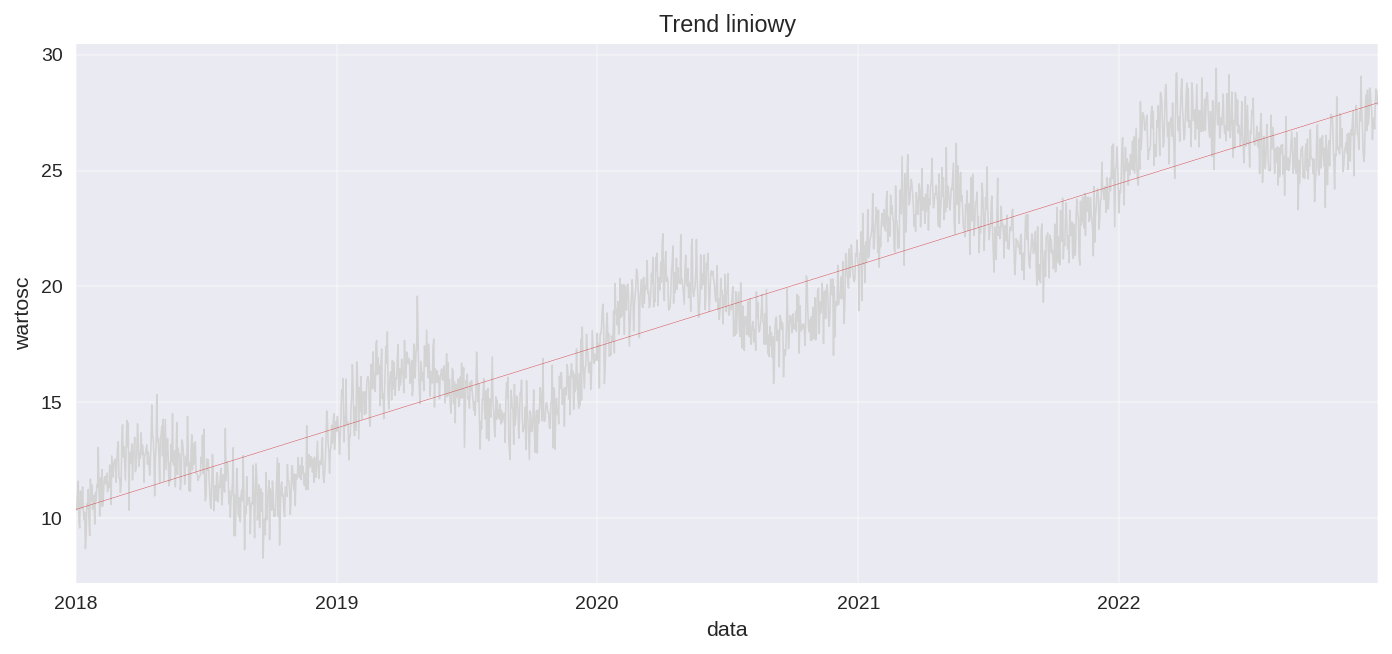

In [11]:
# aproksymacja liniowa trendu dzieki np.polyft
# y_t = a*t +b
a, b = np.polyfit(t, df["y"].to_numpy(), deg=1)

df["trend_lin"] = a * t +b
df["detrended"] = df["y"] - df["trend_lin"]

ax = df["y"].plot(color="lightgray", lw=0.8)
df["trend_lin"].plot(ax=ax, color="tab:red", lw=0.2)
ax.set_title("Trend liniowy")
ax.set_xlabel("data")
ax.set_ylabel("wartosc")
ax.grid(True, alpha=0.3)

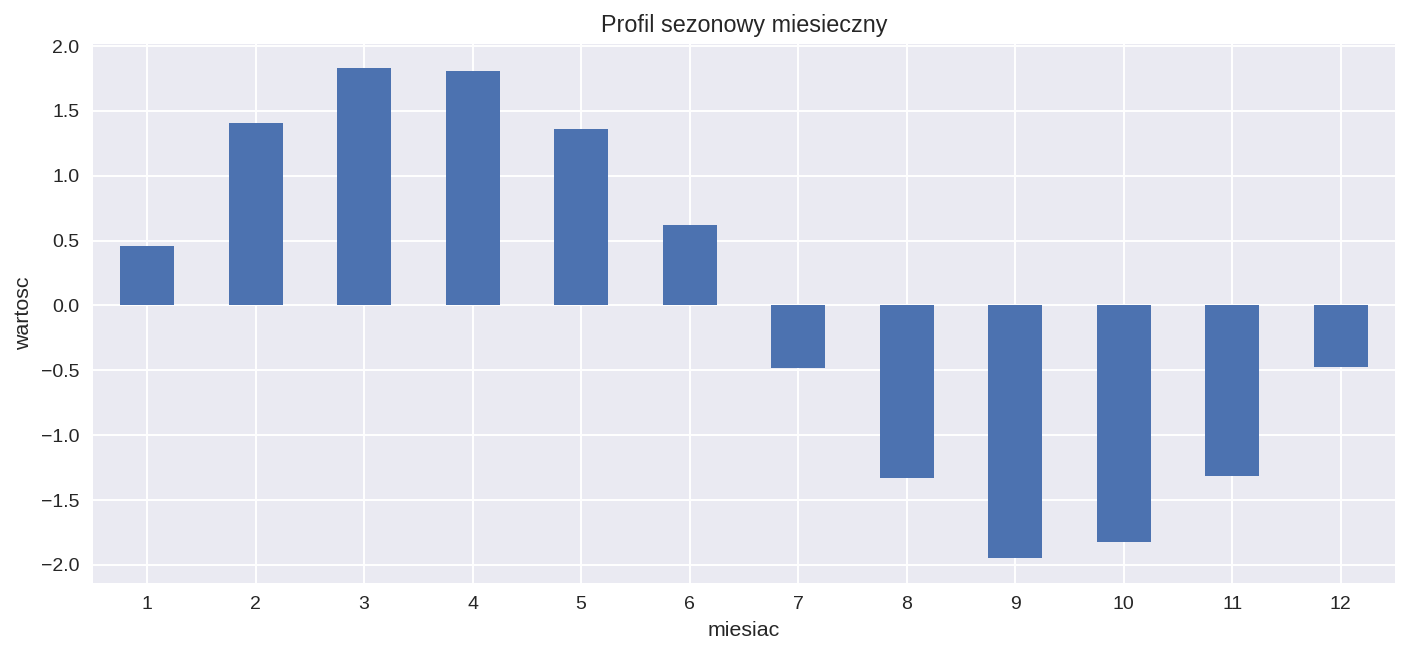

In [12]:
# sezonowosc miesieczna wykres kolumnowy

mies = df.index.month
profil_mies = df["detrended"].groupby(mies).mean()
ax = profil_mies.plot(kind="bar")
ax.set_title("Profil sezonowy miesieczny")
ax.set_xlabel("miesiac")
ax.set_ylabel("wartosc")
ax.grid(True)
plt.xticks(rotation=0)
plt.show()

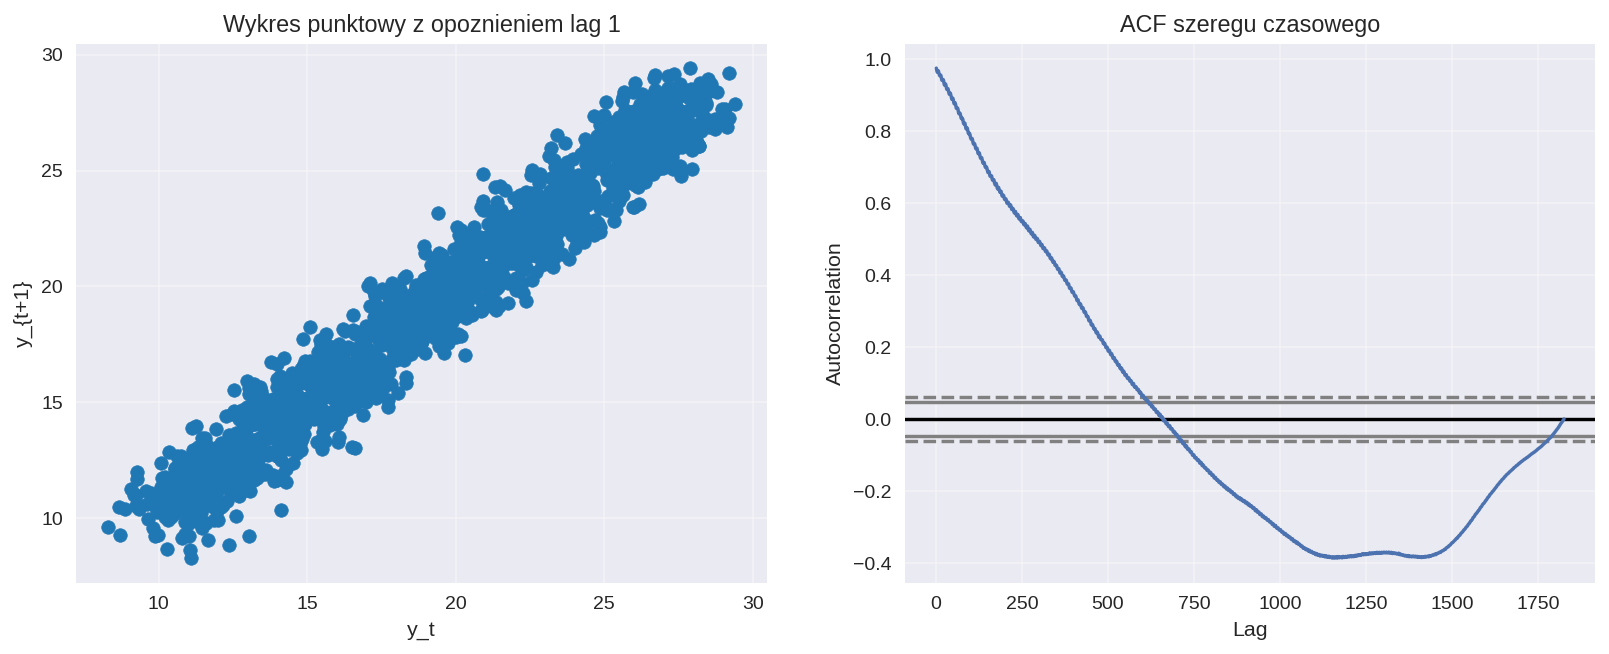

In [14]:
# autokorelacja - ACF - czyli korelacja szeregu w podpowiednim opoznieniu

fig, axes = plt.subplots(1,2,figsize=(14,5))

lag_plot(df["y"], lag=1, ax=axes[0], c="tab:blue")
axes[0].set_title("Wykres punktowy z opoznieniem lag 1")
axes[0].set_xlabel("y_t")
axes[0].set_ylabel("y_{t+1}")
axes[0].grid(True, alpha=0.3)

autocorrelation_plot(df["y"], ax=axes[1])
axes[1].set_title("ACF szeregu czasowego")
axes[1].grid(True, alpha=0.3)
plt.show()